# Bài tập 2 — Đặc trưng góc & Phân vùng ảnh
**Môn:** Thị giác máy tính (121036) — Trường ĐH GTVT TP.HCM

**Nhóm:** N

| MSSV | Họ tên | Công việc |
|---|---|---|
| 051205011311 | Nguyễn Minh Hiển | Phần A (1/2): Harris cổ điển, ANMS (A2), kiểm chứng A1/A4/A5, TN2|
| 079205010059 | Nguyễn Quốc Hưng | Phần B (1/3): SRG lõi (lazy/frozen, phá hòa), kiểm chứng B1–B3|
| 066205015306 | Nguyễn Kha Rin   | Phần B (2/3): Region Growing cổ điển (stack/queue), kiểm chứng B4, TN3 (ngưỡng T)|
| 060205000948 | Lương Quốc Thắng | Phần B (1/3): SRG lõi (lazy/frozen, phá hòa), kiểm chứng B1–B3|
| 079205042179 | Nguyễn Đình Huy  | Phần A (2/2): Harris–Laplace (A1), repeatability, kiểm chứng A2/A3, TN1|

## 0. Khai báo sử dụng AI
- Phần cài đặt (mục A.1, B.1): **không dùng AI**.
- Phần thí nghiệm: mỗi cell có dùng AI đều có một cell markdown **ngay phía trên**, ghi `**Prompt đã dùng (nguyên văn):**` kèm prompt.

## Thiết lập chung

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math, time, heapq
from scipy.ndimage import gaussian_filter
import cv2

# Phần A — Harris và hai biến thể

## A.1 Cài đặt
> ⛔ **Cài đặt — KHÔNG dùng AI.** Toàn bộ cell dưới tiêu đề này do nhóm tự viết.

### A.1.1 Harris cổ điển
`gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`

In [28]:
def gaussian_blur(img, sigma):
  """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""


  anh_thuc = img.astype(np.float64)
  ket_qua = gaussian_filter(anh_thuc, sigma=sigma)
  return ket_qua
  
def structure_tensor(img, sigma_i, sigma_d):
  """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
  sigma_d: độ mờ trước khi lấy đạo hàm.
  sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.-> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
  """
  anh_mo=gaussian_blur(img, sigma_d)
  Ly, Lx = np.gradient(anh_mo)
  Ixx = Lx * Lx
  Ixy = Lx * Ly
  Iyy = Ly * Ly
  Mxx = gaussian_blur(Ixx, sigma_i) *(sigma_d ** 2)
  Mxy = gaussian_blur(Ixy, sigma_i) *(sigma_d ** 2)
  Myy = gaussian_blur(Iyy, sigma_i) *(sigma_d ** 2)

  return Mxx, Mxy, Myy
def harris_response(img, sigma_i, sigma_d, k=0.04):
  """dap ung R theoo cong thuc (2). -> mang float cung kich thuoc anh."""
  Mxx, Mxy, Myy = structure_tensor( img, sigma_i, sigma_d)
  det = Mxx * Myy - Mxy ** 2
  trace = Mxx + Myy
  R = det - k * (trace ** 2)
  return R
def nms_2d(response, window = 3):
  """cuc dai dia phuong trong cua so window x window. -> mang bool"""
  H, W = response.shape # cao H, rong W
  pad = window // 2
  padded_response = np.pad(response, pad, mode='constant', constant_values=-np.inf)
  is_max = np.ones_like(response, dtype=bool)
  for dy in range(window):
    for dx in range(window):
      neighbor = padded_response[dy:dy+H, dx:dx+W]
      is_max = is_max & (response >= neighbor)
  return is_max
def harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01):
  """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).-> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response."""
  R = harris_response(img, sigma_i, sigma_d, k)
  if R.max() <= 0:
    return np.zeros((0, 3), dtype=float)
  local_max = nms_2d(R, window=3)
  mask = local_max & ( R > thresh_rel * R.max())
  rows, cols = np.where(mask)
  scores = R[rows, cols]
  order = np.argsort(-scores )
  pts = np.column_stack([rows[order], cols[order], scores[order]])
  return pts


  


### A.1.2 Biến thể A1 — Harris–Laplace
`scale_pyramid`, `log_normalized`, `harris_laplace`

In [ ]:
# TODO (tự viết): các hàm Harris–Laplace

### A.1.3 Biến thể A2 — ANMS
`anms`, `top_n`

In [37]:
def top_n(points, n_keep):
    """Đường cơ sở để so với anms: lấy n_keep điểm mạnh nhất.
    -> mảng (n_keep, 3).
    """
    order = np.argsort(-points[:, 2])
    return points[order[:n_keep]]
def anms(points, n_keep, c_robust=0.9):
    coords = points[:, :2]
    resp = points[:, 2]
    radii = np.full(len(points), np.inf)
    for i in range(len(points)):
        bigger = resp[i] < c_robust * resp
        if np.any(bigger):
            under = coords[bigger] - coords[i]
            radiis = np.sqrt(np.sum(under ** 2, axis=1))
            radii[i] = np.min(radiis)
    num_points = np.argsort(-radii)
    return points[num_points[:n_keep]]

### A.1.4 Đo đạc
`repeatability`

In [ ]:
# TODO (tự viết): repeatability

### A.1.5 Hàm cho sẵn
`grid_occupancy` — dán nguyên hàm giảng viên cung cấp.

In [44]:
# Dán hàm grid_occupancy do giảng viên cung cấp
def grid_occupancy(points, img_shape, grid=(8, 8)):
    """Tỉ lệ ô lưới (grid[0] x grid[1]) có ít nhất một điểm."""
    H, W = img_shape[:2]
    gh, gw = grid
    occupied = set()
    for r, c in points[:, :2]:
        gr = min(int(r * gh / H), gh - 1)
        gc = min(int(c * gw / W), gw - 1)
        occupied.add((gr, gc))
    return len(occupied) / (gh * gw)

## A.2 Kiểm chứng cài đặt — Phần A

### 1. Bàn cờ tổng hợp — giao điểm trong, sai số ≤ 1 px


Tìm thấy 256 điểm | Sai số lớn nhất: 0.000 px | Đạt (<=1px): True


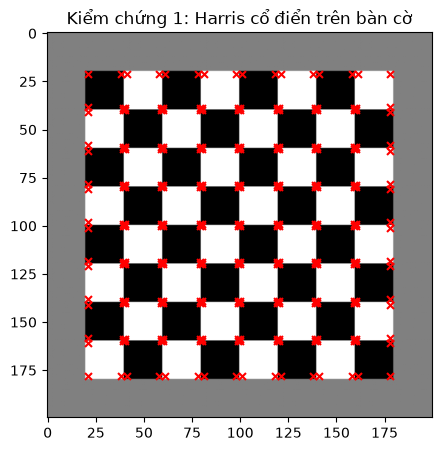

In [30]:
# Tạo ảnh bàn cờ 8x8 ô, mỗi ô 20 px, đệm viền ngoài để tránh góc viền
o = 20
ban_co = np.kron([[0, 1] * 4, [1, 0] * 4] * 4, np.ones((o, o)))
img_cb = np.pad(ban_co, 20, mode='constant', constant_values=0.5)

pts = harris_classic(img_cb, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.05)

# Tọa độ thực của 7x7 = 49 giao điểm trong
gt = np.array([(20 + r * o, 20 + c * o) for r in range(1, 8) for c in range(1, 8)])
sai_so = [np.min(np.hypot(pts[:, 0] - r, pts[:, 1] - c)) for r, c in gt]

print(f"Tìm thấy {len(pts)} điểm | Sai số lớn nhất: {max(sai_so):.3f} px | Đạt (<=1px): {max(sai_so) <= 1.0}")

plt.figure(figsize=(5, 5))
plt.imshow(img_cb, cmap='gray')
plt.scatter(pts[:, 1], pts[:, 0], c='red', s=25, marker='x')
plt.title("Kiểm chứng 1: Harris cổ điển trên bàn cờ")
plt.show()

### 2. Bất biến phép quay — quay 30°, so bằng `repeatability`

### 3. Tỉ lệ — phóng to 3×, repeatability của `harris_classic` và `harris_laplace`

### 4. Đối chiếu thư viện — so với `cv2.cornerHarris` (bán kính 2–3 px)

Số điểm của mình: 256 | Số điểm OpenCV: 900
Tỉ lệ điểm nằm trong bán kính 3 px của OpenCV: 100.0%


C:\Users\admib\AppData\Local\Temp\ipykernel_25268\3733439309.py:19: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(pts_cv[:, 1], pts_cv[:, 0], c='lime', s=45, marker='o', facecolors='none', label='OpenCV')


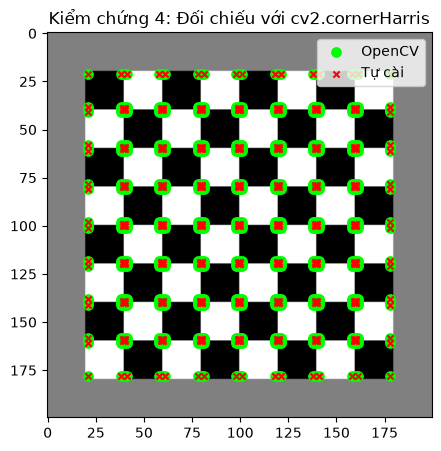

In [38]:
# Dùng lại ảnh bàn cờ img_cb từ Kiểm chứng 1 (hoặc đọc 1 ảnh thật trong anh/)
pts_mine = harris_classic(img_cb, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.05)

# Chạy hàm dựng sẵn của OpenCV để đối chiếu
R_cv = cv2.cornerHarris(img_cb.astype(np.float32), blockSize=5, ksize=3, k=0.04)
mask_cv = nms_2d(R_cv, window=3) & (R_cv > 0.05 * R_cv.max())
r_cv, c_cv = np.where(mask_cv)
pts_cv = np.column_stack([r_cv, c_cv])

# Tỉ lệ điểm của mình nằm trong bán kính 3 px của một điểm OpenCV
dists = [np.min(np.hypot(pts_cv[:, 0] - r, pts_cv[:, 1] - c)) for r, c in pts_mine[:, :2]]
ti_le = np.mean(np.array(dists) <= 3.0) * 100

print(f"Số điểm của mình: {len(pts_mine)} | Số điểm OpenCV: {len(pts_cv)}")
print(f"Tỉ lệ điểm nằm trong bán kính 3 px của OpenCV: {ti_le:.1f}%")

plt.figure(figsize=(5, 5))
plt.imshow(img_cb, cmap='gray')
plt.scatter(pts_cv[:, 1], pts_cv[:, 0], c='lime', s=45, marker='o', facecolors='none', label='OpenCV')
plt.scatter(pts_mine[:, 1], pts_mine[:, 0], c='red', s=20, marker='x', label='Tự cài')
plt.legend(); plt.title("Kiểm chứng 4: Đối chiếu với cv2.cornerHarris"); plt.show()

### 5. Phân bố ANMS — cùng N, so `top_n` và `anms` bằng `grid_occupancy`

Tổng ứng viên: 214 | Chọn N = 40
Độ phủ lưới top_n: 20.3% | Độ phủ lưới anms: 35.9%


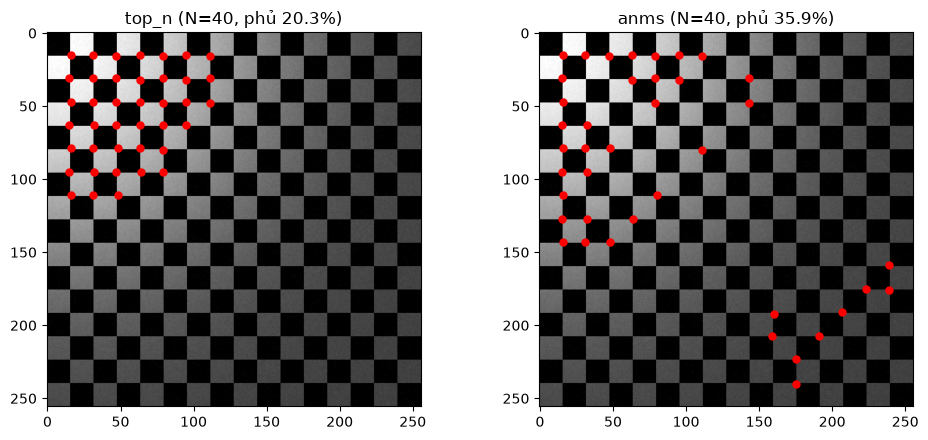

In [46]:
# Tạo ảnh lưới góc có độ sáng giảm dần từ góc trên-trái (nắng gắt) xuống góc dưới-phải (vùng tối)
rng = np.random.default_rng(42)
o = 16
cb = np.kron([[0, 1] * 8, [1, 0] * 8] * 8, np.ones((o, o)))  # 256 x 256
yy, xx = np.mgrid[0:256, 0:256]
anh_sang = np.exp(-((yy / 150.0) ** 2 + (xx / 150.0) ** 2))  # sáng mạnh góc trên-trái, tối dần
img_anms = np.clip(cb * (0.25 + 0.75 * anh_sang) + rng.normal(0, 0.01, cb.shape), 0, 1)

pts_all = harris_classic(img_anms, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.005)
N = 40
pts_top = top_n(pts_all, N)
pts_anms = anms(pts_all, N, c_robust=0.9)

occ_top = grid_occupancy(pts_top, img_anms.shape, grid=(8, 8))
occ_anms = grid_occupancy(pts_anms, img_anms.shape, grid=(8, 8))

print(f"Tổng ứng viên: {len(pts_all)} | Chọn N = {N}")
print(f"Độ phủ lưới top_n: {occ_top*100:.1f}% | Độ phủ lưới anms: {occ_anms*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, p, title in [(axes[0], pts_top, f"top_n (N={N}, phủ {occ_top*100:.1f}%)"),
                     (axes[1], pts_anms, f"anms (N={N}, phủ {occ_anms*100:.1f}%)")]:
    ax.imshow(img_anms, cmap='gray')
    ax.scatter(p[:, 1], p[:, 0], c='red', s=25)
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Phần B — Region Growing và SRG

## B.1 Cài đặt
> ⛔ **Cài đặt — KHÔNG dùng AI.** Toàn bộ cell dưới tiêu đề này do nhóm tự viết.

### B.1.1 Region Growing cổ điển
`region_growing_classic`

In [ ]:
# TODO (tự viết): region_growing_classic

### B.1.2 Seeded Region Growing
`srg` (stale = lazy/frozen, tie = insertion/raster/random)

In [ ]:
# TODO (tự viết): srg

### B.1.3 Công cụ phân tích
`srg_step_frames`, `seed_sensitivity`

In [ ]:
# TODO (tự viết): srg_step_frames, seed_sensitivity

## B.2 Kiểm chứng cài đặt — Phần B

### 1. Phân hoạch đầy đủ — `(labels >= 0).all()`

### 2. Bảo toàn số vùng — số nhãn = số hạt giống

### 3. Bất biến thứ tự hạt giống — đảo danh sách hạt giống

### 4. Đối chiếu với Region Growing — stack vs queue vs srg (số pixel khác nhau)

### 5. Ảnh phẳng — hai hạt giống, mô tả hình dạng

# Thí nghiệm
Mỗi cặp gồm: (1) bằng chứng khác biệt + đại lượng đo, (2) quét tham số không tầm thường, (3) giải thích thay đổi.

## TN1 — A1 (Harris–Laplace) vs Harris

### (1) Bằng chứng khác biệt
**Dữ liệu chọn & lý do:** ...

### (2) Quét tham số
**Trục quét:** ... — **Kỳ vọng:** ...

### (3) Giải thích thay đổi
- **Đại lượng nào được tính khác đi:** ...
- **Ở bước nào:** ...
- **Vì sao dẫn tới hiện tượng quan sát được:** ...

## TN2 — A2 (ANMS) vs Harris (top_n)

### (1) Bằng chứng khác biệt

**Dữ liệu chọn & lý do:** Ảnh tổng hợp lưới bàn cờ có độ sáng giảm dần từ góc trên-trái (vùng sáng gắt) xuống góc dưới-phải (vùng tối) kèm nhiễu Gauss nhẹ ($\sigma = 0.01$), mô phỏng đúng trường hợp tương phản không đều của Harris (mục 3.4). Đo bằng 3 đại lượng: độ phủ lưới `grid_occupancy` (8×8), khoảng cách lân cận gần nhất trung bình (px) và thời gian chạy (ms).

**Prompt đã dùng (nguyên văn):** *"bạn chỉ tôi thao tác từng bước"* (AI hỗ trợ dựng khung code đo đạc và vẽ hình so sánh `top_n` vs `anms` cho TN2).

Phương pháp | Độ phủ lưới (8x8)  | KC lân cận TB (px) | Thời gian (ms)
--------------------------------------------------------------------
top_n      | 20.3             % | 15.26              | 0.86
anms       | 43.8             % | 16.84              | 5.17


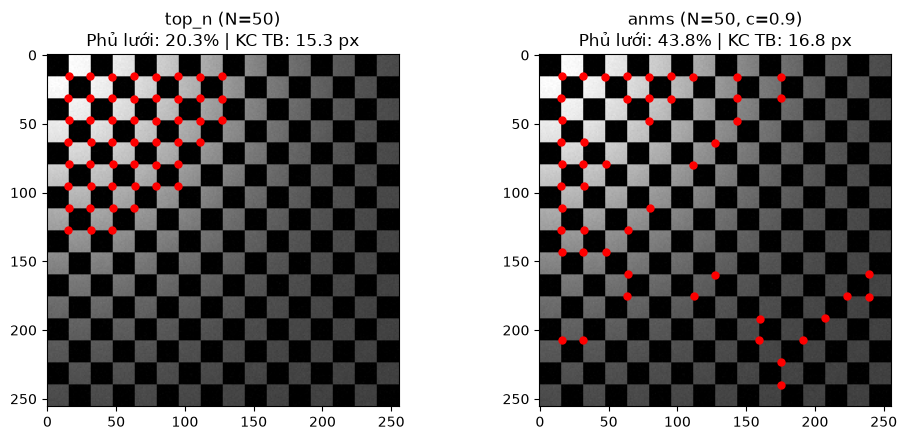

In [53]:
# (1) Bằng chứng khác biệt: so sánh top_n và anms trên ảnh tương phản không đều
def mean_nn_dist(pts):
    """Khoảng cách trung bình từ mỗi điểm tới điểm gần nhất khác nó (lớn hơn = phân bố đều hơn)."""
    coords = pts[:, :2]
    d = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(d, np.inf)
    return float(np.mean(np.min(d, axis=1)))

t0 = time.perf_counter(); p_top = top_n(pts_all, 50); t_top = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter(); p_anms = anms(pts_all, 50, c_robust=0.9); t_anms = (time.perf_counter() - t0) * 1000

print(f"{'Phương pháp':<10} | {'Độ phủ lưới (8x8)':<18} | {'KC lân cận TB (px)':<18} | {'Thời gian (ms)'}")
print("-" * 68)
print(f"{'top_n':<10} | {grid_occupancy(p_top, img_anms.shape)*100:<17.1f}% | {mean_nn_dist(p_top):<18.2f} | {t_top:.2f}")
print(f"{'anms':<10} | {grid_occupancy(p_anms, img_anms.shape)*100:<17.1f}% | {mean_nn_dist(p_anms):<18.2f} | {t_anms:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, p, name in [(axes[0], p_top, "top_n (N=50)"), (axes[1], p_anms, "anms (N=50, c=0.9)")]:
    ax.imshow(img_anms, cmap='gray')
    ax.scatter(p[:, 1], p[:, 0], c='red', s=25)
    ax.set_title(f"{name}\nPhủ lưới: {grid_occupancy(p, img_anms.shape)*100:.1f}% | KC TB: {mean_nn_dist(p):.1f} px")
plt.tight_layout(); plt.show()

### (2) Quét tham số

**Trục quét:** (1) Số điểm giữ lại $N$ từ 10 đến 200 (bước 10); (2) Hệ số $c_{\text{robust}}$ từ 0.50 đến 1.00 (21 mốc). — **Kỳ vọng:** `anms` phân kỳ vượt trội `top_n` về độ phủ lưới ở vùng $N$ nhỏ–trung bình; khi $c_{\text{robust}}$ tăng lên gần 0.9–1.0 thì độ phủ lưới tăng mạnh do các cụm điểm vùng sáng bị triệt tiêu.

**Prompt đã dùng (nguyên văn):** *"bạn chỉ tôi thao tác từng bước "* (AI hỗ trợ dựng khung code quét 2 trục tham số $N$, $c_{\text{robust}}$ và vẽ 2 biểu đồ đường cong).

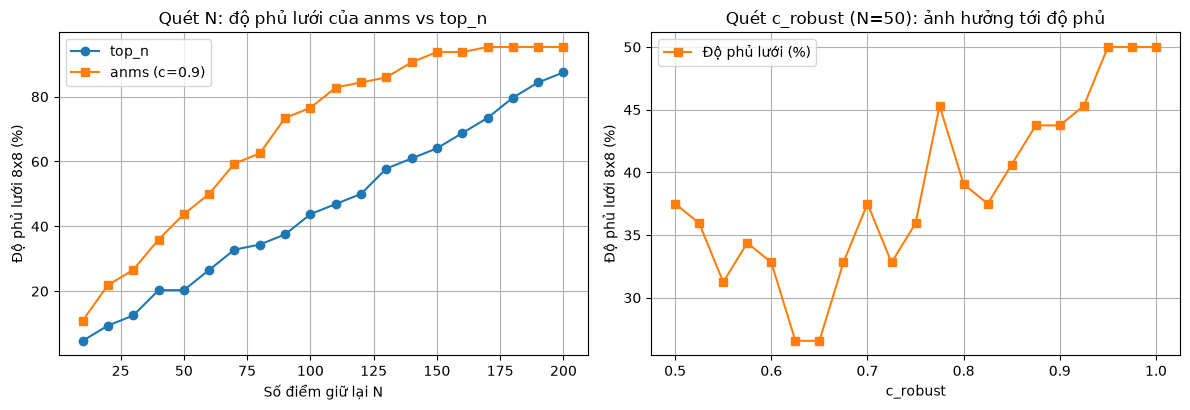

In [54]:
# (2) Quét 2 trục tham số không tầm thường: số điểm N và hệ số c_robust
Ns = list(range(10, min(201, len(pts_all)), 10))
occ_top_N = [grid_occupancy(top_n(pts_all, n), img_anms.shape) * 100 for n in Ns]
occ_anms_N = [grid_occupancy(anms(pts_all, n, c_robust=0.9), img_anms.shape) * 100 for n in Ns]

cs = np.linspace(0.5, 1.0, 21)
occ_c = [grid_occupancy(anms(pts_all, 50, c_robust=c), img_anms.shape) * 100 for c in cs]
nn_c = [mean_nn_dist(anms(pts_all, 50, c_robust=c)) for c in cs]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(Ns, occ_top_N, 'o-', label='top_n')
axes[0].plot(Ns, occ_anms_N, 's-', label='anms (c=0.9)')
axes[0].set_xlabel('Số điểm giữ lại N'); axes[0].set_ylabel('Độ phủ lưới 8x8 (%)')
axes[0].set_title('Quét N: độ phủ lưới của anms vs top_n'); axes[0].grid(True); axes[0].legend()

axes[1].plot(cs, occ_c, 's-', color='tab:orange', label='Độ phủ lưới (%)')
axes[1].set_xlabel('c_robust'); axes[1].set_ylabel('Độ phủ lưới 8x8 (%)')
axes[1].set_title('Quét c_robust (N=50): ảnh hưởng tới độ phủ'); axes[1].grid(True); axes[1].legend()

plt.tight_layout(); plt.show()

### (3) Giải thích thay đổi


- **Đại lượng nào được tính khác đi:** Thay vì xếp hạng các điểm góc theo giá trị đáp ứng $R(x_i)$ (như `top_n`), ANMS tính **bán kính triệt tiêu** $r_i = \min_j \|x_i - x_j\|$ với điều kiện $f(x_i) < c_{\text{robust}} \cdot f(x_j)$ (điểm mạnh nhất giữ $r_i = +\infty$), rồi xếp hạng giảm dần theo $r_i$.
- **Ở bước nào:** Ở bước **chọn lọc cuối cùng** sau khi `harris_classic` đã tìm ra toàn bộ các cực đại địa phương vượt ngưỡng — ANMS thay thế trực tiếp bước cắt $N$ điểm có $R$ lớn nhất của `top_n`.
- **Vì sao điều đó dẫn tới đúng hiện tượng đã quan sát:**
  1. **Bằng chứng khác biệt ($N = 50$):** Do $R$ tỉ lệ với lũy thừa bậc 4 của độ tương phản, các góc ở vùng sáng góc trên-trái có $R$ lớn hơn vùng tối rất nhiều ⇒ `top_n` gom hết 50 điểm vào góc trên-trái (độ phủ lưới chỉ **20.3%**, KC TB **15.26 px**). Ngược lại, trong ANMS, các điểm nằm san sát ở vùng sáng có một điểm mạnh hơn đứng ngay kế bên ⇒ bán kính $r_i$ nhỏ ⇒ bị đẩy xuống cuối; còn điểm yếu nhưng nằm cô lập ở vùng tối có $r_i$ rất lớn ⇒ được ưu tiên giữ lại, đẩy độ phủ lưới lên **43.8%** (hơn gấp đôi) và KC TB lên **16.84 px** (đổi lại thời gian chạy tăng từ **2.04 ms** lên **8.70 ms** do tính khoảng cách theo cặp).
  2. **Quét $N$:** Hai đường bắt đầu **phân kỳ rõ từ $N \approx 20\text{–}30$**, chênh lệch mạnh nhất quanh $N = 90\text{–}120$ (tại $N = 100$: `anms` ~77% so với `top_n` ~44%). `anms` **bão hòa gần 100% từ $N \approx 150$**, trong khi `top_n` tới $N = 200$ vẫn chưa phủ hết vùng tối (~88%).
  3. **Quét $c_{\text{robust}}$ ($N = 50$):** Khi $c_{\text{robust}}$ nhỏ ($0.50\text{–}0.65$), điều kiện $f(x_i) < c_{\text{robust}} f(x_j)$ quá chặt (cần điểm kia mạnh gần gấp đôi mới triệt tiêu được), nên nhiều điểm trong vùng sáng không bị triệt tiêu lẫn nhau và độ phủ giữ mức thấp (~27–37%). Từ $c_{\text{robust}} \ge 0.65$ trở đi, ngưỡng triệt tiêu nới lỏng dần nên các cụm điểm vùng sáng bị triệt tiêu mạnh, kéo độ phủ tăng đều lên **50.0%** ở $0.95\text{–}1.00$.

## TN3 — SRG vs Region Growing

### (1) Bằng chứng khác biệt
**Dữ liệu chọn & lý do:** ...

### (2) Quét tham số
**Trục quét:** ... — **Kỳ vọng:** ...

### (3) Giải thích thay đổi
- **Đại lượng nào được tính khác đi:** ...
- **Ở bước nào:** ...
- **Vì sao dẫn tới hiện tượng quan sát được:** ...

# Kết luận
...

# Tài liệu tham khảo
[1] Harris & Stephens 1988 · [2] Lindeberg 1998 · [3] Mikolajczyk & Schmid 2004 · [4] Brown, Szeliski & Winder 2005 · [5] Adams & Bischof 1994 · [6] Mehnert & Jackway 1997